# Mini Diffusion Model: DDPM to DDIM

This notebook implements a simplified diffusion model on MNIST.

Configuration:

- Dataset: MNIST
- Diffusion steps: T = 100
- Beta schedule: linearly increasing from 0.0001 to 0.02
- Model: timestep-conditioned CNN
- Sampling: DDPM and DDIM

In [21]:
import math
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

torch.manual_seed(5996)
np.random.seed(5996)

Using device: cuda


In [22]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))  # Converts pixels approximately to [-1, 1]
])

train_dataset = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

train_loader = DataLoader(
    train_dataset,
    batch_size=128,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

print("Training samples:", len(train_dataset))

Training samples: 60000


In [23]:
T = 100

beta_start = 0.0001
beta_end = 0.02

betas = torch.linspace(
    beta_start,
    beta_end,
    T,
    device=device
)

alphas = 1.0 - betas

alpha_bars = torch.cumprod(alphas, dim=0)

sqrt_alpha_bars = torch.sqrt(alpha_bars)
sqrt_one_minus_alpha_bars = torch.sqrt(1.0 - alpha_bars)

# Useful for reverse DDPM sampling
sqrt_recip_alphas = torch.sqrt(1.0 / alphas)

posterior_variance = (
    betas *
    (1.0 - torch.cat([
        torch.tensor([1.0], device=device),
        alpha_bars[:-1]
    ])) /
    (1.0 - alpha_bars)
)

print("Number of diffusion steps:", T)
print("First beta:", betas[0].item())
print("Last beta:", betas[-1].item())

Number of diffusion steps: 100
First beta: 9.999999747378752e-05
Last beta: 0.019999999552965164


In [24]:
def extract(values, timesteps, x_shape):
    """
    Extract values corresponding to each timestep and reshape
    them so they can broadcast with image tensors.
    """
    batch_size = timesteps.shape[0]

    out = values.gather(0, timesteps)

    return out.reshape(
        batch_size,
        *((1,) * (len(x_shape) - 1))
    )


def forward_diffusion(x0, t, noise=None):
    """
    Add noise to clean images x0 at timestep t.

    x_t = sqrt(alpha_bar_t) * x0
          + sqrt(1 - alpha_bar_t) * noise
    """

    if noise is None:
        noise = torch.randn_like(x0)

    sqrt_ab = extract(
        sqrt_alpha_bars,
        t,
        x0.shape
    )

    sqrt_one_minus_ab = extract(
        sqrt_one_minus_alpha_bars,
        t,
        x0.shape
    )

    xt = sqrt_ab * x0 + sqrt_one_minus_ab * noise

    return xt, noise

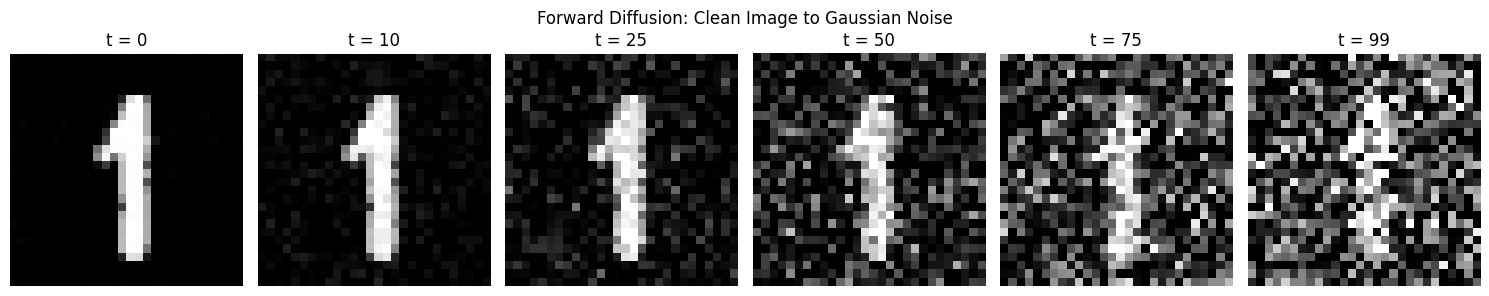

In [25]:
images, labels = next(iter(train_loader))

x0 = images[0:1].to(device)

timesteps_to_show = [0, 10, 25, 50, 75, 99]

fig, axes = plt.subplots(1, len(timesteps_to_show), figsize=(15, 3))

for ax, t_value in zip(axes, timesteps_to_show):
    t = torch.tensor([t_value], device=device)

    xt, noise = forward_diffusion(x0, t)

    # Convert from [-1, 1] back to [0, 1] for display
    display_image = (xt[0, 0].detach().cpu() + 1) / 2
    display_image = display_image.clamp(0, 1)

    ax.imshow(display_image, cmap="gray")
    ax.set_title(f"t = {t_value}")
    ax.axis("off")

plt.suptitle("Forward Diffusion: Clean Image to Gaussian Noise")
plt.tight_layout()
plt.show()

As the timestep increases, more Gaussian noise is added to the original image.

At timestep t = 0, the image is almost clean. At large timesteps, the image contains very little information about the original digit and resembles Gaussian noise.

The forward process is fixed and does not require training. The neural network will later learn the reverse process: predicting the noise so that the original image can be reconstructed.

## Timestep-Conditioned Noise Prediction Network

The CNN predicts the Gaussian noise added to an image.

The timestep is embedded using sinusoidal features and injected into
the convolutional layers so that the model knows how noisy the image is.

In [26]:
class SinusoidalTimeEmbedding(nn.Module):
    def __init__(self, embedding_dim):
        super().__init__()
        self.embedding_dim = embedding_dim

    def forward(self, timesteps):
        half_dim = self.embedding_dim // 2

        exponent = -math.log(10000) / (half_dim - 1)

        frequencies = torch.exp(
            torch.arange(half_dim, device=timesteps.device) * exponent
        )

        angles = timesteps.float()[:, None] * frequencies[None, :]

        embedding = torch.cat([
            torch.sin(angles),
            torch.cos(angles)
        ], dim=1)

        return embedding

In [27]:
class NoisePredictorCNN(nn.Module):
    def __init__(self):
        super().__init__()

        time_embedding_dim = 64
        hidden_dim = 64

        self.time_embedding = SinusoidalTimeEmbedding(
            time_embedding_dim
        )

        self.time_mlp = nn.Sequential(
            nn.Linear(time_embedding_dim, 128),
            nn.SiLU(),
            nn.Linear(128, 128)
        )

        # At least four convolutional layers
        self.conv1 = nn.Conv2d(
            in_channels=1,
            out_channels=64,
            kernel_size=3,
            padding=1
        )

        self.conv2 = nn.Conv2d(
            in_channels=64,
            out_channels=128,
            kernel_size=3,
            padding=1
        )

        self.conv3 = nn.Conv2d(
            in_channels=128,
            out_channels=128,
            kernel_size=3,
            padding=1
        )

        self.conv4 = nn.Conv2d(
            in_channels=128,
            out_channels=64,
            kernel_size=3,
            padding=1
        )

        self.conv5 = nn.Conv2d(
            in_channels=64,
            out_channels=1,
            kernel_size=3,
            padding=1
        )

        self.time_to_conv2 = nn.Linear(128, 128)
        self.time_to_conv3 = nn.Linear(128, 128)

    def forward(self, x, t):
        # Embed timestep
        t_embedding = self.time_embedding(t)
        t_embedding = self.time_mlp(t_embedding)

        # First convolution
        h = F.relu(self.conv1(x))

        # Second convolution + timestep conditioning
        h = self.conv2(h)

        time_features = self.time_to_conv2(t_embedding)
        time_features = time_features[:, :, None, None]

        h = h + time_features
        h = F.relu(h)

        # Third convolution + timestep conditioning
        h = self.conv3(h)

        time_features = self.time_to_conv3(t_embedding)
        time_features = time_features[:, :, None, None]

        h = h + time_features
        h = F.relu(h)

        # Remaining convolutions
        h = F.relu(self.conv4(h))
        output = self.conv5(h)

        return output

In [28]:
model = NoisePredictorCNN().to(device)

test_images, _ = next(iter(train_loader))
test_images = test_images[:4].to(device)

test_timesteps = torch.randint(
    low=0,
    high=T,
    size=(4,),
    device=device
)

predicted_noise = model(test_images, test_timesteps)

print("Input shape:", test_images.shape)
print("Output shape:", predicted_noise.shape)

Input shape: torch.Size([4, 1, 28, 28])
Output shape: torch.Size([4, 1, 28, 28])


## Training Objective

For every image, a random timestep is selected and Gaussian noise is added.

The CNN receives the noisy image and timestep and predicts the noise.

The model is trained using mean squared error:

L = MSE(actual_noise, predicted_noise)

In [29]:
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=1e-3
)

num_epochs = 50
loss_history = []

model.train()

for epoch in range(num_epochs):
    total_loss = 0.0

    for images, _ in train_loader:
        images = images.to(device)

        batch_size = images.shape[0]

        # Random timestep for every image
        t = torch.randint(
            low=0,
            high=T,
            size=(batch_size,),
            device=device
        )

        # Generate noisy images
        noisy_images, actual_noise = forward_diffusion(
            images,
            t
        )

        # Predict the noise
        predicted_noise = model(
            noisy_images,
            t
        )

        # MSE noise prediction loss
        loss = F.mse_loss(
            predicted_noise,
            actual_noise
        )

        optimizer.zero_grad()
        loss.backward()

        # Helps prevent unstable gradients
        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        optimizer.step()

        total_loss += loss.item()

    average_loss = total_loss / len(train_loader)
    loss_history.append(average_loss)

    print(
        f"Epoch [{epoch + 1}/{num_epochs}] "
        f"Loss: {average_loss:.6f}"
    )

Epoch [1/50] Loss: 0.162754
Epoch [2/50] Loss: 0.078938
Epoch [3/50] Loss: 0.072296
Epoch [4/50] Loss: 0.069085
Epoch [5/50] Loss: 0.067971
Epoch [6/50] Loss: 0.066061
Epoch [7/50] Loss: 0.066419
Epoch [8/50] Loss: 0.064417
Epoch [9/50] Loss: 0.063934
Epoch [10/50] Loss: 0.064057
Epoch [11/50] Loss: 0.063626
Epoch [12/50] Loss: 0.062749
Epoch [13/50] Loss: 0.062452
Epoch [14/50] Loss: 0.062812
Epoch [15/50] Loss: 0.062302
Epoch [16/50] Loss: 0.061993
Epoch [17/50] Loss: 0.061342
Epoch [18/50] Loss: 0.061266
Epoch [19/50] Loss: 0.061237
Epoch [20/50] Loss: 0.061892
Epoch [21/50] Loss: 0.061185
Epoch [22/50] Loss: 0.060749
Epoch [23/50] Loss: 0.060472
Epoch [24/50] Loss: 0.060768
Epoch [25/50] Loss: 0.060768
Epoch [26/50] Loss: 0.060329
Epoch [27/50] Loss: 0.060604
Epoch [28/50] Loss: 0.060222
Epoch [29/50] Loss: 0.060329
Epoch [30/50] Loss: 0.060117
Epoch [31/50] Loss: 0.060063
Epoch [32/50] Loss: 0.059663
Epoch [33/50] Loss: 0.059766
Epoch [34/50] Loss: 0.059860
Epoch [35/50] Loss: 0.0

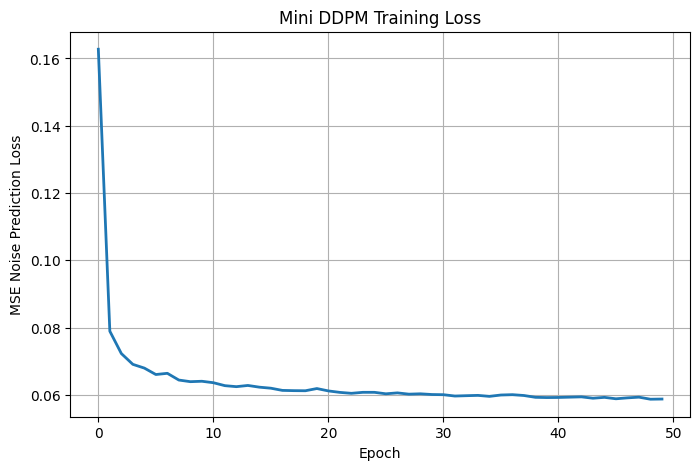

In [30]:
plt.figure(figsize=(8, 5))

plt.plot(
    loss_history,
    linewidth=2
)

plt.xlabel("Epoch")
plt.ylabel("MSE Noise Prediction Loss")
plt.title("Mini DDPM Training Loss")
plt.grid(True)
plt.show()

In [31]:
torch.save(
    model.state_dict(),
    "mini_ddpm_mnist.pth"
)

print("Model saved successfully.")

Model saved successfully.


The model is trained to predict the noise added during the forward diffusion process.

A decreasing MSE loss indicates that the CNN is learning the relationship between
the noisy image, the diffusion timestep, and the noise that was added.

The timestep conditioning is important because images at early timesteps contain
little noise, while images at late timesteps contain much more noise.

## DDPM Reverse Sampling

DDPM sampling starts with Gaussian noise and iteratively removes noise.

At every timestep, the trained CNN predicts the noise in the current image.
The reverse equation then uses this prediction to estimate a less noisy image.

In [32]:
@torch.no_grad()
def sample_ddpm(model, num_samples=16):
    model.eval()

    # Start from pure Gaussian noise x_T
    x = torch.randn(
        num_samples,
        1,
        28,
        28,
        device=device
    )

    for time_step in reversed(range(T)):
        t = torch.full(
            size=(num_samples,),
            fill_value=time_step,
            device=device,
            dtype=torch.long
        )

        # Predict noise
        predicted_noise = model(x, t)

        beta_t = betas[time_step]
        sqrt_one_minus_ab_t = sqrt_one_minus_alpha_bars[time_step]
        sqrt_recip_alpha_t = sqrt_recip_alphas[time_step]

        # DDPM mean
        model_mean = sqrt_recip_alpha_t * (
            x -
            (beta_t / sqrt_one_minus_ab_t) * predicted_noise
        )

        if time_step > 0:
            # Add reverse-process randomness
            noise = torch.randn_like(x)

            variance = posterior_variance[time_step]

            x = model_mean + torch.sqrt(variance) * noise
        else:
            # At t = 0, do not add additional noise
            x = model_mean

    return x

In [33]:
ddpm_images = sample_ddpm(
    model,
    num_samples=16
)

print("Generated image tensor shape:", ddpm_images.shape)

Generated image tensor shape: torch.Size([16, 1, 28, 28])


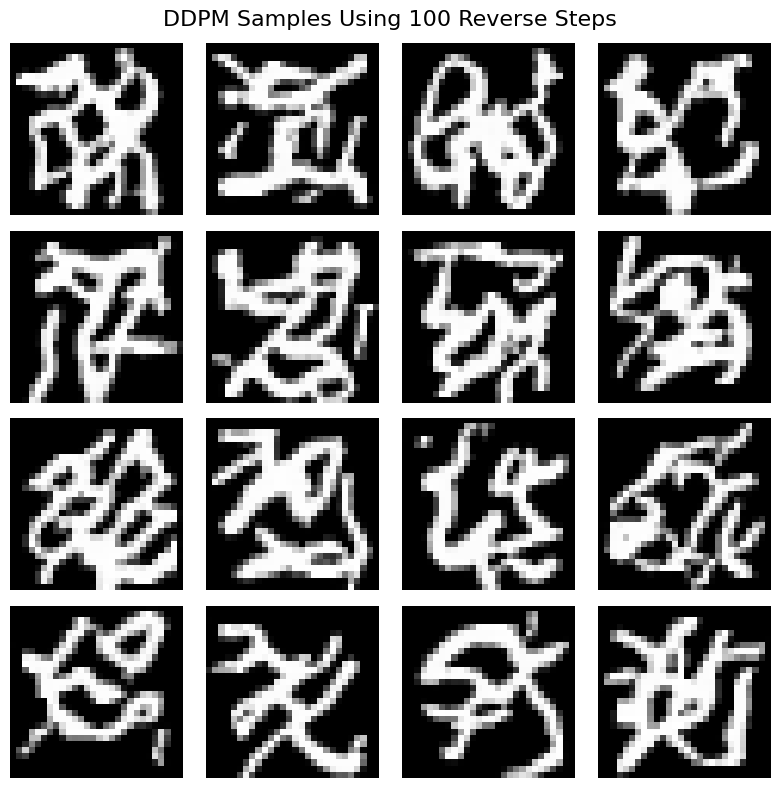

In [34]:
def show_images(images, title, nrow=4):
    images = images.detach().cpu()

    # Convert from [-1, 1] to [0, 1]
    images = (images + 1) / 2
    images = images.clamp(0, 1)

    fig, axes = plt.subplots(
        nrow,
        nrow,
        figsize=(8, 8)
    )

    for i, ax in enumerate(axes.flat):
        ax.imshow(
            images[i, 0],
            cmap="gray"
        )
        ax.axis("off")

    plt.suptitle(title, fontsize=16)
    plt.tight_layout()
    plt.show()


show_images(
    ddpm_images,
    "DDPM Samples Using 100 Reverse Steps"
)

DDPM sampling uses all 100 reverse diffusion steps.

At each step, the model predicts the noise in the current image and removes part
of that noise. Random noise is also added during intermediate reverse steps,
which makes DDPM sampling stochastic.

Using more reverse steps usually produces smoother and more reliable samples,
but it requires more computation.

## DDIM Sampling

DDIM uses a selected subset of the diffusion timesteps.

Instead of reversing all 100 steps, we can reverse using:

- 50 timesteps
- 20 timesteps

With eta = 0, DDIM sampling is deterministic for a fixed starting noise image.

In [35]:
@torch.no_grad()
def sample_ddim(
    model,
    num_samples=16,
    num_steps=50,
    eta=0.0,
    initial_noise=None
):
    model.eval()

    if initial_noise is None:
        x = torch.randn(
            num_samples,
            1,
            28,
            28,
            device=device
        )
    else:
        x = initial_noise.clone().to(device)
        num_samples = x.shape[0]

    # Select evenly spaced timesteps
    selected_timesteps = torch.linspace(
        0,
        T - 1,
        num_steps,
        device=device
    ).long()

    # Reverse order: high noise to low noise
    selected_timesteps = selected_timesteps.flip(0)

    for i, current_t in enumerate(selected_timesteps):
        current_t_value = current_t.item()

        # Previous selected timestep
        if i + 1 < len(selected_timesteps):
            previous_t = selected_timesteps[i + 1]
            previous_t_value = previous_t.item()
        else:
            # Final step goes to clean image
            previous_t_value = -1

        t = torch.full(
            size=(num_samples,),
            fill_value=current_t_value,
            device=device,
            dtype=torch.long
        )

        # Predict noise
        predicted_noise = model(x, t)

        alpha_bar_current = alpha_bars[current_t_value]

        if previous_t_value >= 0:
            alpha_bar_previous = alpha_bars[previous_t_value]
        else:
            alpha_bar_previous = torch.tensor(
                1.0,
                device=device
            )

        # Estimate clean image x_0
        predicted_x0 = (
            x -
            torch.sqrt(1.0 - alpha_bar_current) * predicted_noise
        ) / torch.sqrt(alpha_bar_current)

        # Prevent extreme values
        predicted_x0 = predicted_x0.clamp(-1.0, 1.0)

        # DDIM variance
        sigma = eta * torch.sqrt(
            (1.0 - alpha_bar_previous) /
            (1.0 - alpha_bar_current)
        ) * torch.sqrt(
            1.0 -
            alpha_bar_current / alpha_bar_previous
        )

        # Direction pointing toward the noisy image
        direction = torch.sqrt(
            torch.clamp(
                1.0 - alpha_bar_previous - sigma ** 2,
                min=0.0
            )
        ) * predicted_noise

        # Compute previous image
        x = (
            torch.sqrt(alpha_bar_previous) * predicted_x0
            + direction
        )

        # Add stochasticity only when eta > 0
        if eta > 0 and previous_t_value >= 0:
            noise = torch.randn_like(x)
            x = x + sigma * noise

    return x

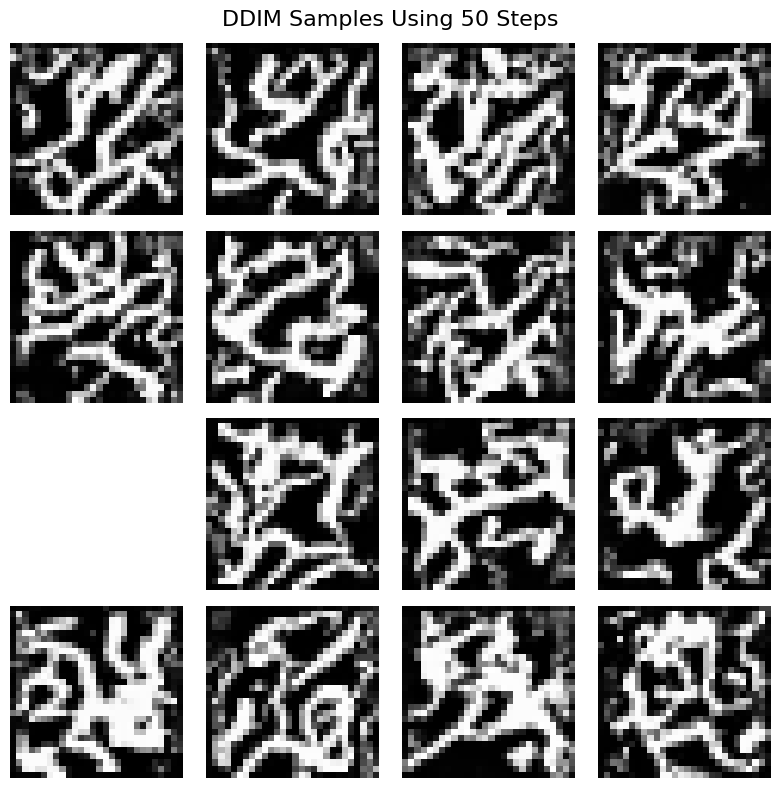

In [36]:
ddim_50_images = sample_ddim(
    model=model,
    num_samples=16,
    num_steps=50,
    eta=0.0
)

show_images(
    ddim_50_images,
    "DDIM Samples Using 50 Steps"
)

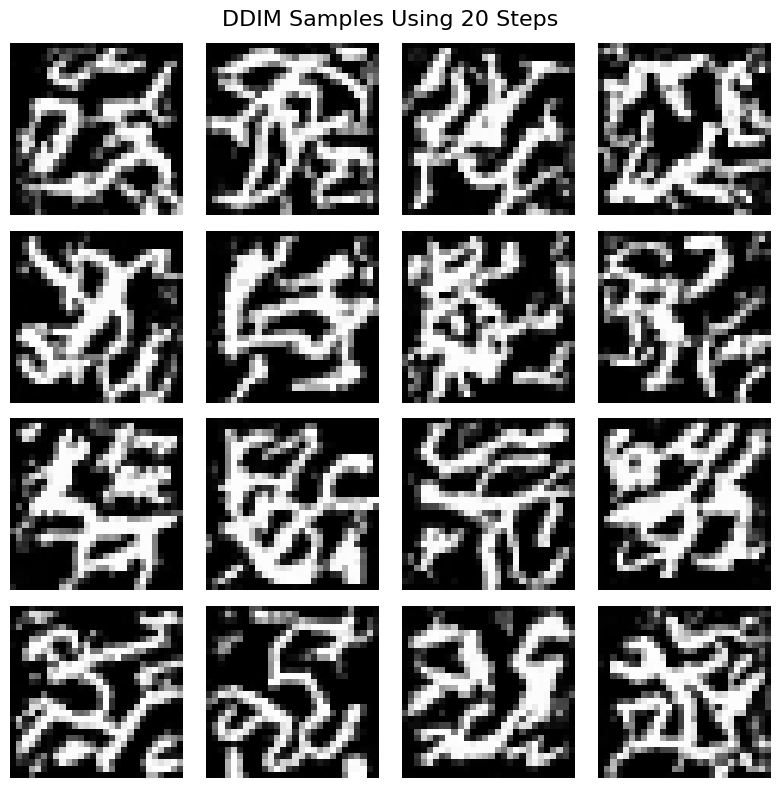

In [37]:
ddim_20_images = sample_ddim(
    model=model,
    num_samples=16,
    num_steps=20,
    eta=0.0
)

show_images(
    ddim_20_images,
    "DDIM Samples Using 20 Steps"
)

In [38]:
num_samples = 16

same_initial_noise = torch.randn(
    num_samples,
    1,
    28,
    28,
    device=device
)

ddpm_images = sample_ddpm(
    model,
    num_samples=num_samples
)

ddim_50_images = sample_ddim(
    model,
    num_samples=num_samples,
    num_steps=50,
    eta=0.0,
    initial_noise=same_initial_noise
)

ddim_20_images = sample_ddim(
    model,
    num_samples=num_samples,
    num_steps=20,
    eta=0.0,
    initial_noise=same_initial_noise
)

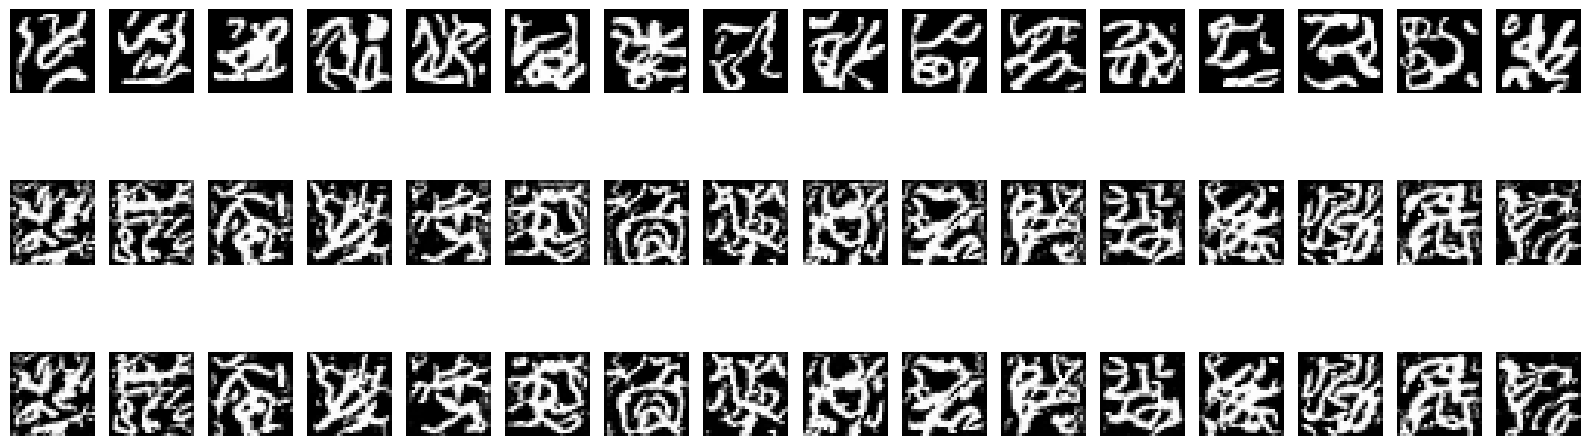

In [39]:
def display_comparison(image_sets, titles):
    image_sets = [
        ((images.detach().cpu() + 1) / 2).clamp(0, 1)
        for images in image_sets
    ]

    num_rows = len(image_sets)
    num_cols = image_sets[0].shape[0]

    fig, axes = plt.subplots(
        num_rows,
        num_cols,
        figsize=(16, 6)
    )

    if num_rows == 1:
        axes = np.expand_dims(axes, axis=0)

    for row in range(num_rows):
        for col in range(num_cols):
            axes[row, col].imshow(
                image_sets[row][col, 0],
                cmap="gray"
            )
            axes[row, col].axis("off")

        axes[row, 0].set_ylabel(
            titles[row],
            fontsize=12
        )

    plt.tight_layout()
    plt.show()


display_comparison(
    [
        ddpm_images,
        ddim_50_images,
        ddim_20_images
    ],
    [
        "DDPM - 100 steps",
        "DDIM - 50 steps",
        "DDIM - 20 steps"
    ]
)

In [41]:
import time

def measure_sampling_time(sampling_function):
    start_time = time.time()
    images = sampling_function()
    end_time = time.time()

    return images, end_time - start_time


_, ddpm_time = measure_sampling_time(
    lambda: sample_ddpm(
        model,
        num_samples=16
    )
)

_, ddim_50_time = measure_sampling_time(
    lambda: sample_ddim(
        model,
        num_samples=16,
        num_steps=50,
        eta=0.0
    )
)

_, ddim_20_time = measure_sampling_time(
    lambda: sample_ddim(
        model,
        num_samples=16,
        num_steps=20,
        eta=0.0
    )
)

print(f"DDPM 100-step time: {ddpm_time:.3f} seconds")
print(f"DDIM 50-step time:  {ddim_50_time:.3f} seconds")
print(f"DDIM 20-step time:  {ddim_20_time:.3f} seconds")

DDPM 100-step time: 0.110 seconds
DDIM 50-step time:  0.069 seconds
DDIM 20-step time:  0.028 seconds


## Discussion

DDPM sampling uses all 100 reverse diffusion steps and adds random noise
during intermediate reverse steps. It generally produces reliable and smooth
samples, but it is computationally slower.

DDIM sampling uses a selected subset of timesteps. Therefore, DDIM can generate
samples much faster using only 50 or 20 reverse steps.

The 50-step DDIM samples usually maintain reasonable image quality while requiring
approximately half as many reverse steps as DDPM. The 20-step DDIM sampler is
faster still, but the generated digits may be blurrier, less detailed, or less
consistent.

With eta = 0, DDIM is deterministic for a fixed initial noise tensor. In
contrast, DDPM includes stochastic noise during the reverse process, so repeated
samples may differ even when the model is unchanged.

Overall, DDIM provides a speed-quality tradeoff: fewer sampling steps produce
faster generation, while more steps generally improve reconstruction quality.